In [3]:
# ==========================================
# 0. ENVIRONMENT & OCR CONFIGURATION
# ==========================================

from pathlib import Path
import importlib.util
import shutil
import subprocess

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from io import BytesIO

import pyarrow.parquet as pq
import cv2

# Project paths
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "ICDAR2019-SROIE" / "data"

TRAIN_PATH = DATA_DIR / "train-00000-of-00001.parquet"
TEST_PATH = DATA_DIR / "test-00000-of-00001.parquet"
SPLIT_PATH = PROJECT_DIR / "splits.csv"

# Check files
print("PROJECT:", PROJECT_DIR)
print("TRAIN exists:", TRAIN_PATH.exists())
print("TEST exists:", TEST_PATH.exists())
print("SPLITS exists:", SPLIT_PATH.exists())

# Check Python packages
print("\n========== PYTHON PACKAGES ==========")

for package in ["cv2", "pytesseract", "PIL", "pandas", "pyarrow"]:
    print(f"{package}:",
          importlib.util.find_spec(package) is not None)

# Check Tesseract executable
print("\n========== TESSERACT ENGINE ==========")

tesseract_path = shutil.which("tesseract")
print("Tesseract path:", tesseract_path)

if tesseract_path:
    result = subprocess.run(
        ["tesseract", "--version"],
        capture_output=True,
        text=True
    )
    print(result.stdout.splitlines()[0])
else:
    print("TESSERACT NOT INSTALLED")

PROJECT: /app
TRAIN exists: True
TEST exists: True
SPLITS exists: True

========== PYTHON PACKAGES ==========
cv2: True
pytesseract: True
PIL: True
pandas: True
pyarrow: True

========== TESSERACT ENGINE ==========
Tesseract path: /usr/bin/tesseract
tesseract 5.5.0


Invoice key: X00016469612
Image size: (463, 1013)
Image mode: RGB


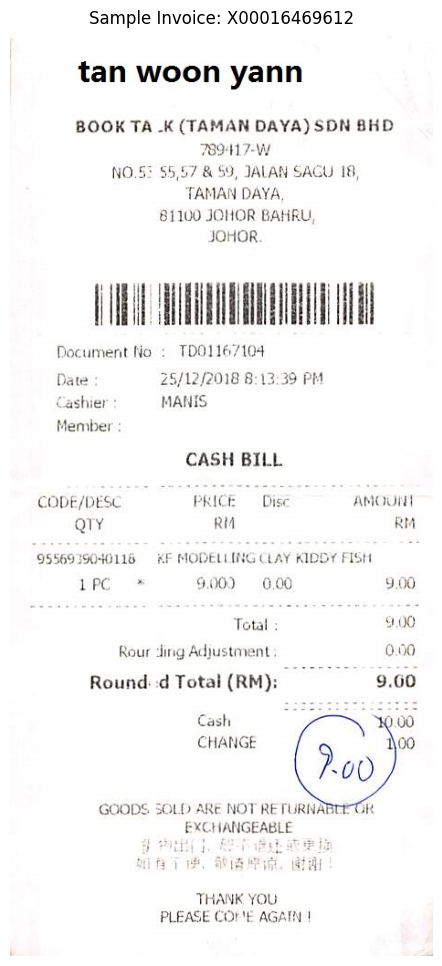

In [4]:
# ==========================================
# 1. LOAD SAMPLE INVOICE IMAGE
# ==========================================

# Đọc danh sách phân chia dữ liệu
splits_df = pd.read_csv(SPLIT_PATH)

# Lấy danh sách key thuộc tập Train
train_keys = set(
    splits_df.loc[splits_df["split"] == "train", "key"].astype(str)
)

# Đọc metadata của tập Train
train_df = pq.read_table(
    TRAIN_PATH,
    columns=["key", "image_size", "entities", "words", "bboxes"]
).to_pandas()

# Chọn một hóa đơn thuộc tập Train
sample_row = train_df[
    train_df["key"].astype(str).isin(train_keys)
].iloc[0]

sample_key = str(sample_row["key"])

# Đọc dữ liệu ảnh từ Parquet
image_table = pq.read_table(
    TRAIN_PATH,
    columns=["key", "image"]
)

image_records = image_table.to_pylist()

# Tìm ảnh tương ứng với sample_key
sample_image_record = next(
    record for record in image_records
    if str(record["key"]) == sample_key
)

# Giải mã bytes thành ảnh RGB
image_bytes = sample_image_record["image"]["bytes"]

sample_image = Image.open(
    BytesIO(image_bytes)
).convert("RGB")

# Hiển thị thông tin và ảnh
print("Invoice key:", sample_key)
print("Image size:", sample_image.size)
print("Image mode:", sample_image.mode)

plt.figure(figsize=(10, 12))
plt.imshow(sample_image)
plt.title(f"Sample Invoice: {sample_key}")
plt.axis("off")
plt.show()

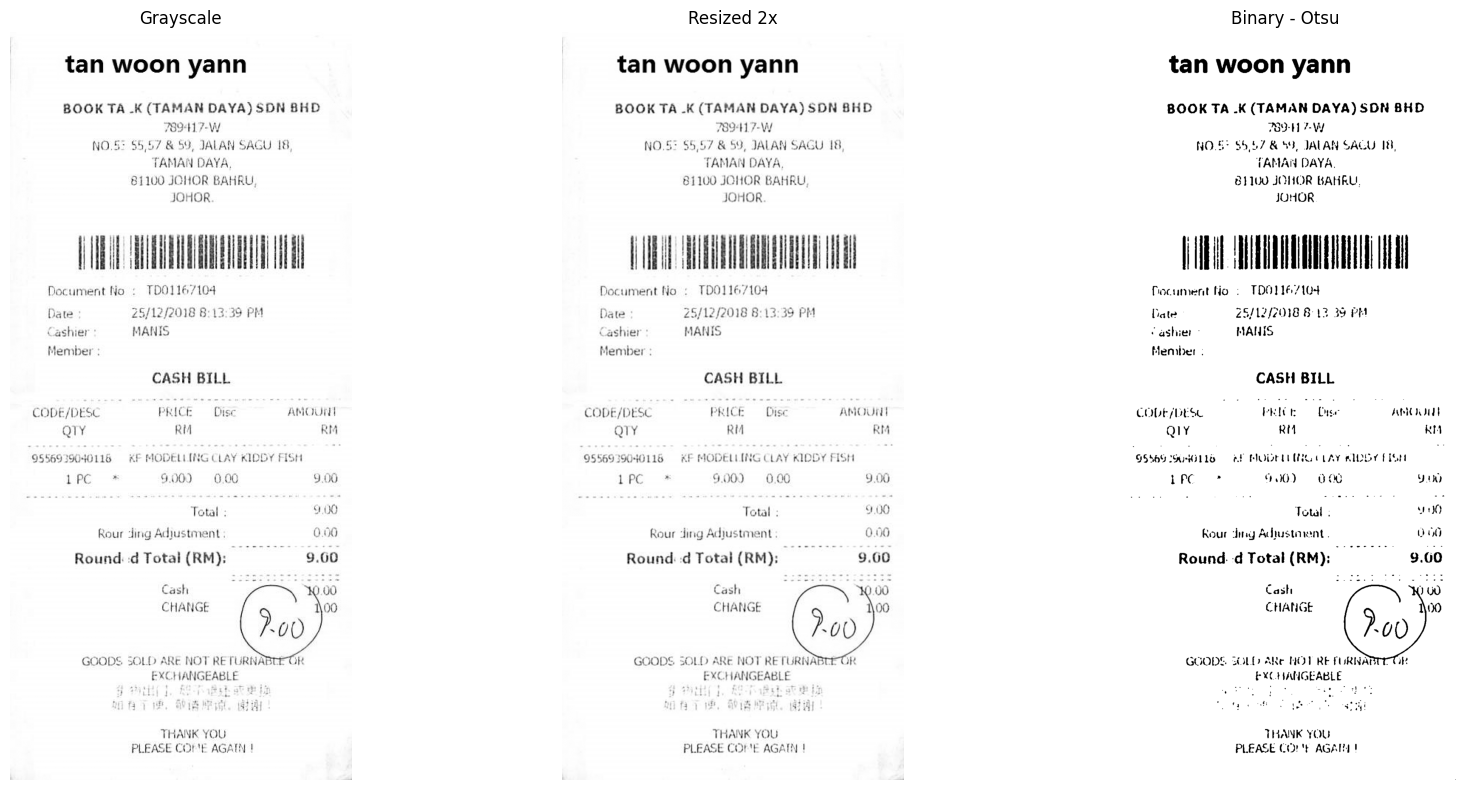

Original size: (463, 1013)
Grayscale size: (1013, 463)
Processed size: (2026, 926)


In [5]:
# ==========================================
# 2. IMAGE PREPROCESSING
# ==========================================

# 1. Convert RGB to Grayscale
gray_image = cv2.cvtColor(
    np.array(sample_image),
    cv2.COLOR_RGB2GRAY
)

# 2. Resize image (scale 2x)
scale_factor = 2

resized_image = cv2.resize(
    gray_image,
    None,
    fx=scale_factor,
    fy=scale_factor,
    interpolation=cv2.INTER_CUBIC
)

# 3. Remove noise
denoised_image = cv2.GaussianBlur(
    resized_image,
    (3, 3),
    0
)

# 4. Apply Otsu Thresholding
_, binary_image = cv2.threshold(
    denoised_image,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# 5. Display preprocessing results
fig, axes = plt.subplots(1, 3, figsize=(18, 8))

axes[0].imshow(gray_image, cmap="gray")
axes[0].set_title("Grayscale")

axes[1].imshow(resized_image, cmap="gray")
axes[1].set_title("Resized 2x")

axes[2].imshow(binary_image, cmap="gray")
axes[2].set_title("Binary - Otsu")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original size:", sample_image.size)
print("Grayscale size:", gray_image.shape)
print("Processed size:", binary_image.shape)

In [7]:
# ==========================================
# 3. INITIALIZE TESSERACT OCR
# ==========================================

import pytesseract

# Kiểm tra phiên bản Tesseract
print("Tesseract version:")
print(pytesseract.get_tesseract_version())

# Kiểm tra các ngôn ngữ được hỗ trợ
available_languages = pytesseract.get_languages(config="")

print("\nAvailable languages:")
print(available_languages)

# Kiểm tra tiếng Anh
assert "eng" in available_languages, (
    "English language data (eng) is not installed."
)

# Cấu hình OCR
OCR_CONFIG = "--oem 3 --psm 6"

print("\nOCR configuration:", OCR_CONFIG)
print("Tesseract initialized successfully!")

Tesseract version:
5.5.0

Available languages:
['eng', 'osd', 'vie']

OCR configuration: --oem 3 --psm 6
Tesseract initialized successfully!


In [8]:
# ==========================================
# 4. RUN OCR ON DIFFERENT IMAGE VERSIONS
# ==========================================

# OCR trên ảnh gốc
ocr_original = pytesseract.image_to_string(
    sample_image,
    lang="eng",
    config=OCR_CONFIG
)

# OCR trên ảnh Grayscale
ocr_gray = pytesseract.image_to_string(
    gray_image,
    lang="eng",
    config=OCR_CONFIG
)

# OCR trên ảnh Binary
ocr_binary = pytesseract.image_to_string(
    binary_image,
    lang="eng",
    config=OCR_CONFIG
)

# Lưu kết quả vào dictionary
ocr_results = {
    "original": ocr_original,
    "grayscale": ocr_gray,
    "binary": ocr_binary
}

print("OCR completed!")
print("Original characters:", len(ocr_original))
print("Grayscale characters:", len(ocr_gray))
print("Binary characters:", len(ocr_binary))

OCR completed!
Original characters: 498
Grayscale characters: 497
Binary characters: 507


In [9]:
# ==========================================
# 5. DISPLAY OCR RESULTS
# ==========================================

for method, text_result in ocr_results.items():

    print("\n" + "=" * 60)
    print(f"OCR RESULT: {method.upper()}")
    print("=" * 60)

    print(text_result)


OCR RESULT: ORIGINAL
tan woon yann
BOOK TA -K (TAMAN DAYA) SDN BHD
7B 7-W
NO.5: 55,57 & 59, JALAN SAGU 18,
TAMAN DAYA,
81100 JOHOR BAHRU,
JOHOR.
apts |
WAM MUTANT
Document Ho : TDO1167104
Date 25/12/2018 8:13:39 PH
Cashier MANIS
Member
CASH BILL
CODE/DESC : PRICE Dise AMOUHT
Qiy Ri RM
955693040116 KF MODELLING Cay KIDDY FISH :
1 PC * 9.00) 0,00 9.00
Total : 9.00
Rour ding Adjustment 0.00
Round. :d Total (RM): 9.60
Cash yy 40.00
CHANGE 00
00
GOODS SOLD ARE NOT RETURNAP aK
EXCHANGEABLE
THANK YOU
PLEASE COME AGAIN t


OCR RESULT: GRAYSCALE
tan woon yann
BOOK TA -K (TAMAN DAYA) SDN BHD
78941 7-W
NO.5? 55,57 & 59, JALAN SAGU 18,
TAMAN DAYA,
81100 JOHOR BAHRU,
JOHOR.
WAM MUTE A
Ea
Document Ho : TDO1167104
Date 25/12/2018 8:13:39 PH
Cashier MANIS
Member
CASH BILL
CODE/DESC : PRICE Dise AMOUHT
Qiy Ri RM
9556930040116 KF MODELLING cay KIDDY FISH :
1 PC * 9.00) 0,00 9.00
Total 9.00
Rour ding Adjustment 0.00
Round: :d Total (RM): 9.60
Cash “y 40.00
CHANGE 00
00
GOODS SOLD ARE NOT RETURNAP aK
EXC

In [10]:
# ==========================================
# 6. OCR CONFIDENCE EVALUATION
# ==========================================

ocr_confidence_results = {}

image_versions = {
    "original": sample_image,
    "grayscale": gray_image,
    "binary": binary_image
}

for method, image_input in image_versions.items():

    data = pytesseract.image_to_data(
        image_input,
        lang="eng",
        config=OCR_CONFIG,
        output_type=pytesseract.Output.DATAFRAME
    )

    # Loại bỏ những dòng không có văn bản
    data = data.dropna(subset=["text"])

    # Chỉ giữ các từ có nội dung
    data = data[data["text"].astype(str).str.strip() != ""]

    # Chuyển confidence về dạng số
    data["conf"] = pd.to_numeric(
        data["conf"],
        errors="coerce"
    )

    # Loại bỏ confidence không hợp lệ
    valid_conf = data.loc[
        data["conf"] >= 0,
        "conf"
    ]

    mean_confidence = (
        valid_conf.mean()
        if len(valid_conf) > 0
        else np.nan
    )

    ocr_confidence_results[method] = {
        "word_count": len(valid_conf),
        "mean_confidence": mean_confidence
    }

confidence_df = pd.DataFrame(
    ocr_confidence_results
).T

display(confidence_df)

,word_count,mean_confidence
original,94.0,70.333869
grayscale,93.0,70.564295
binary,103.0,51.345059


In [11]:
# ==========================================
# 7. COMPARE OCR WITH GROUND TRUTH
# ==========================================

import re

# Lấy Ground Truth của hóa đơn mẫu
ground_truth_words = sample_row["words"]

ground_truth_text = " ".join(
    str(word) for word in ground_truth_words
)

# Chuẩn hóa văn bản
def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def normalize_tokens(text):
    return re.findall(r"\w+", normalize_text(text))


# Tính Word Error Rate (WER)
def calculate_wer(reference, hypothesis):

    ref = normalize_tokens(reference)
    hyp = normalize_tokens(hypothesis)

    n = len(ref)
    m = len(hyp)

    dp = np.zeros((n + 1, m + 1), dtype=int)

    for i in range(n + 1):
        dp[i, 0] = i

    for j in range(m + 1):
        dp[0, j] = j

    for i in range(1, n + 1):
        for j in range(1, m + 1):

            if ref[i - 1] == hyp[j - 1]:
                cost = 0
            else:
                cost = 1

            dp[i, j] = min(
                dp[i - 1, j] + 1,       # Deletion
                dp[i, j - 1] + 1,       # Insertion
                dp[i - 1, j - 1] + cost # Substitution
            )

    wer = dp[n, m] / max(n, 1)

    return wer


# Tính WER cho từng phiên bản ảnh
wer_results = []

for method, predicted_text in ocr_results.items():

    wer = calculate_wer(
        ground_truth_text,
        predicted_text
    )

    wer_results.append({
        "method": method,
        "WER": wer,
        "Accuracy (%)": (1 - wer) * 100
    })

wer_df = pd.DataFrame(wer_results)

display(wer_df)

print("\nGROUND TRUTH:")
print(ground_truth_text)

print("\nOCR OUTPUT - GRAYSCALE:")
print(ocr_gray)

,method,WER,Accuracy (%)
0,original,0.351648,64.835165
1,grayscale,0.362637,63.736264
2,binary,0.692308,30.769231



GROUND TRUTH:
TAN WOON YANN BOOK TA .K(TAMAN DAYA) SDN BND 789417-W NO.53 55 TAMAN DAYA 81100 JOHOR BAHRU JOHOR. DOCUMENT NO : TD01167104 DATE: 25/12/2018 8:13:39 PM CASHIER: MANIS MEMBER: CASH BILL CODE/DESC PRICE DISC AMOUNT QTY RM RM 9556939040116 KF MODELLING CLAY KIDDY FISH 1 PC * 9.000 0.00 9.00 TOTAL: ROUR DING ADJUSTMENT: 0.00 ROUND D TOTAL (RM): 9.00 CASH 10.00 CHANGE 1.00 GOODS SOLD ARE NOT RETURNABLE OR EXCHANGEABLE *** *** THANK YOU PLEASE COME AGAIN ! 9.00

OCR OUTPUT - GRAYSCALE:
tan woon yann
BOOK TA -K (TAMAN DAYA) SDN BHD
78941 7-W
NO.5? 55,57 & 59, JALAN SAGU 18,
TAMAN DAYA,
81100 JOHOR BAHRU,
JOHOR.
WAM MUTE A
Ea
Document Ho : TDO1167104
Date 25/12/2018 8:13:39 PH
Cashier MANIS
Member
CASH BILL
CODE/DESC : PRICE Dise AMOUHT
Qiy Ri RM
9556930040116 KF MODELLING cay KIDDY FISH :
1 PC * 9.00) 0,00 9.00
Total 9.00
Rour ding Adjustment 0.00
Round: :d Total (RM): 9.60
Cash “y 40.00
CHANGE 00
00
GOODS SOLD ARE NOT RETURNAP aK
EXCHANGEABLE
THANK YOU.
PLEASE COME AGAIN t



In [12]:
# ==========================================
# 8. SAVE SAMPLE OCR RESULTS
# ==========================================

import json

OUTPUT_DIR = PROJECT_DIR / "outputs" / "ocr"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

sample_result = {
    "key": sample_key,
    "ground_truth": ground_truth_text,
    "ocr_original": ocr_original,
    "ocr_grayscale": ocr_gray,
    "ocr_binary": ocr_binary,
    "confidence": {
        method: {
            "word_count": int(result["word_count"]),
            "mean_confidence": (
                float(result["mean_confidence"])
                if pd.notna(result["mean_confidence"])
                else None
            )
        }
        for method, result in ocr_confidence_results.items()
    }
}

SAMPLE_OUTPUT_PATH = OUTPUT_DIR / "sample_ocr.json"

with open(
    SAMPLE_OUTPUT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        sample_result,
        file,
        ensure_ascii=False,
        indent=4
    )

print("Sample OCR saved to:", SAMPLE_OUTPUT_PATH)

Sample OCR saved to: /app/outputs/ocr/sample_ocr.json


In [ ]:
# ==========================================
# 9. RUN OCR ON TRAIN AND VALIDATION DATA
# ==========================================

import time

# Xác định các key thuộc Train và Validation
selected_splits = splits_df[
    splits_df["split"].isin(["train", "validation"])
].copy()

split_mapping = dict(
    zip(
        selected_splits["key"].astype(str),
        selected_splits["split"]
    )
)

# Đọc ảnh từ Parquet
ocr_image_table = pq.read_table(
    TRAIN_PATH,
    columns=["key", "image"]
)

ocr_image_records = ocr_image_table.to_pylist()

# Chỉ giữ ảnh thuộc Train và Validation
selected_records = [
    record
    for record in ocr_image_records
    if str(record["key"]) in split_mapping
]

print("Total images to process:", len(selected_records))
print("\nSplit distribution:")
print(selected_splits["split"].value_counts())

# Hàm tiền xử lý ảnh
def preprocess_for_ocr(image):

    image_array = np.array(image.convert("RGB"))

    gray = cv2.cvtColor(
        image_array,
        cv2.COLOR_RGB2GRAY
    )

    resized = cv2.resize(
        gray,
        None,
        fx=2,
        fy=2,
        interpolation=cv2.INTER_CUBIC
    )

    return resized


# Chạy OCR trên toàn bộ dữ liệu
batch_ocr_results = []

start_time = time.time()

for index, record in enumerate(selected_records, start=1):

    invoice_key = str(record["key"])
    split_name = split_mapping[invoice_key]

    try:
        # Đọc ảnh
        image_bytes = record["image"]["bytes"]

        image = Image.open(
            BytesIO(image_bytes)
        ).convert("RGB")

        # Tiền xử lý
        processed_image = preprocess_for_ocr(image)

        # Nhận diện văn bản
        recognized_text = pytesseract.image_to_string(
            processed_image,
            lang="eng",
            config=OCR_CONFIG
        )

        batch_ocr_results.append({
            "key": invoice_key,
            "split": split_name,
            "ocr_text": recognized_text,
            "status": "success"
        })

    except Exception as error:

        batch_ocr_results.append({
            "key": invoice_key,
            "split": split_name,
            "ocr_text": "",
            "status": "failed",
            "error": str(error)
        })

    # Hiển thị tiến độ
    if index % 25 == 0 or index == len(selected_records):
        print(
            f"Processed {index}/{len(selected_records)} invoices"
        )

# Chuyển kết quả thành DataFrame
batch_ocr_df = pd.DataFrame(batch_ocr_results)

elapsed_time = time.time() - start_time

print("\nOCR BATCH COMPLETED")
print("Total processed:", len(batch_ocr_df))
print("Elapsed time:", round(elapsed_time, 2), "seconds")

display(batch_ocr_df.head())

Total images to process: 626

Split distribution:
split
train         501
validation    125
Name: count, dtype: int64
Processed 25/626 invoices
Processed 50/626 invoices
Processed 75/626 invoices
Processed 100/626 invoices
Processed 125/626 invoices
Processed 150/626 invoices
Processed 175/626 invoices
Processed 200/626 invoices
Processed 225/626 invoices
Processed 250/626 invoices
Processed 275/626 invoices
Processed 300/626 invoices
Processed 325/626 invoices
Processed 350/626 invoices
Processed 375/626 invoices
Processed 400/626 invoices
Processed 425/626 invoices
Processed 450/626 invoices
Processed 475/626 invoices
Processed 500/626 invoices
Processed 525/626 invoices
Processed 550/626 invoices
Processed 575/626 invoices
Processed 600/626 invoices
Processed 625/626 invoices
Processed 626/626 invoices

OCR BATCH COMPLETED
Total processed: 626
Elapsed time: 1933.69 seconds


,key,split,ocr_text,status
0,X00016469612,train,tan woon yann\nBOOK TA -K (TAMAN DAYA) SDN BHD...,success
1,X00016469619,train,"tan woon yann\nINDAH GIFT & HOME BECO\n27, JAL...",success
2,X00016469620,train,tan woon yann\nMR O.1.Y. (JOHOR) SDN BHD\n(CO....,success
3,X00016469622,train,tan woon yann\nYONGFATT ENTERPRISE\n(JM0517726...,success
4,X00016469623,train,tan woon yann\nMR O.T.Y. GM) SDN BHD\n(CO.REG ...,success


In [ ]:
# ==========================================
# 10. VALIDATE AND SAVE BATCH OCR RESULTS
# ==========================================

# Thống kê trạng thái OCR
print("========== OCR STATUS ==========")

print(
    batch_ocr_df["status"].value_counts(dropna=False)
)

# Thống kê theo từng tập dữ liệu
print("\n========== SPLIT DISTRIBUTION ==========")

display(
    pd.crosstab(
        batch_ocr_df["split"],
        batch_ocr_df["status"],
        margins=True
    )
)

# Kiểm tra dữ liệu thiếu
print("\n========== DATA QUALITY ==========")

print(
    "Missing invoice keys:",
    batch_ocr_df["key"].isna().sum()
)

print(
    "Duplicate invoice keys:",
    batch_ocr_df["key"].duplicated().sum()
)

print(
    "Empty OCR results:",
    (
        batch_ocr_df["ocr_text"]
        .fillna("")
        .str.strip()
        .eq("")
    ).sum()
)

# Lưu kết quả OCR
BATCH_OUTPUT_PATH = OUTPUT_DIR / "train_validation_ocr.csv"

batch_ocr_df.to_csv(
    BATCH_OUTPUT_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved OCR results to:")
print(BATCH_OUTPUT_PATH)

# Kiểm tra số lượng dữ liệu
assert batch_ocr_df["key"].nunique() == len(batch_ocr_df)

assert set(batch_ocr_df["split"].unique()).issubset(
    {"train", "validation"}
)

print("\nOCR DATA VALIDATION COMPLETED!")

========== OCR STATUS ==========
status
success    626
Name: count, dtype: int64

========== SPLIT DISTRIBUTION ==========


status,success,All
split,,
train,501,501
validation,125,125
All,626,626



========== DATA QUALITY ==========
Missing invoice keys: 0
Duplicate invoice keys: 0
Empty OCR results: 1

Saved OCR results to:
/app/outputs/ocr/train_validation_ocr.csv

OCR DATA VALIDATION COMPLETED!
